# Task 3

Importing the file

In [ ]:
# Cell 1 — imports and settings
from pathlib import Path
import time
import csv
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = Path("data") / "task03_objects.jpg"
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
TARGET_WIDTH = 800
GROUND_TRUTH = 9          # counted by hand: clay figure, triangle, box, marker, ball,
                          # tape roll, badge, booklet, sharpener (badge touches booklet)
MIN_AREA = 300            # px; regions smaller than this are treated as noise (justified below)
print("OpenCV version:", cv2.__version__)
# the following cells shows there are 
# Largest 12 region areas, px: [5893, 5238, 3671, 3168, 2282, 1803, 1404, 1330, 633, 314, 278, 159]
# As the object number is 9 considering first 9 largest areas the
# rest is noise.


OpenCV version: 5.0.0


Cell 2 — load, resize, grayscale, binarize (objects = white)

In [ ]:
image = cv2.imread(str(IMAGE_PATH), cv2.IMREAD_COLOR)
if image is None:
    raise FileNotFoundError(f"Could not read the image: {IMAGE_PATH}")
# From previous steps Resize the image to a fixed width while maintaining the aspect ratio,
#  convert it to grayscale, and apply Gaussian blur to reduce noise
h, w = image.shape[:2]
resized = cv2.resize(image, (TARGET_WIDTH, round(h * TARGET_WIDTH / w)), interpolation=cv2.INTER_AREA)
gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
gray_blur = cv2.GaussianBlur(gray, (5, 5), 0)

# applying Otsu's thresholding to convert the image to binary and saved the image as binary input

t_otsu, binary = cv2.threshold(gray_blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
_ = cv2.imwrite(str(RESULTS_DIR / "task03_binary_input.png"), binary)

# Print some statistics about the image and the binary mask
print(f"Original {w} x {h} -> resized {resized.shape[1]} x {resized.shape[0]}")
print(f"Gray: mean {gray.mean():.1f}, std {gray.std():.1f} | Otsu T = {t_otsu:.0f}")
print(f"White (object) pixels: {100 * cv2.countNonZero(binary) / binary.size:.1f}%")

Original 4000 x 3000 -> resized 800 x 600
Gray: mean 201.5, std 28.3 | Otsu T = 159
White (object) pixels: 5.7%


Cell 3 — count regions before morphology + area distribution

Before morphology: 47 regions in total, 10 with area >= 300 px (ground truth: 9)
Largest 12 region areas, px: [5893, 5238, 3671, 3168, 2282, 1803, 1404, 1330, 633, 314, 278, 159]


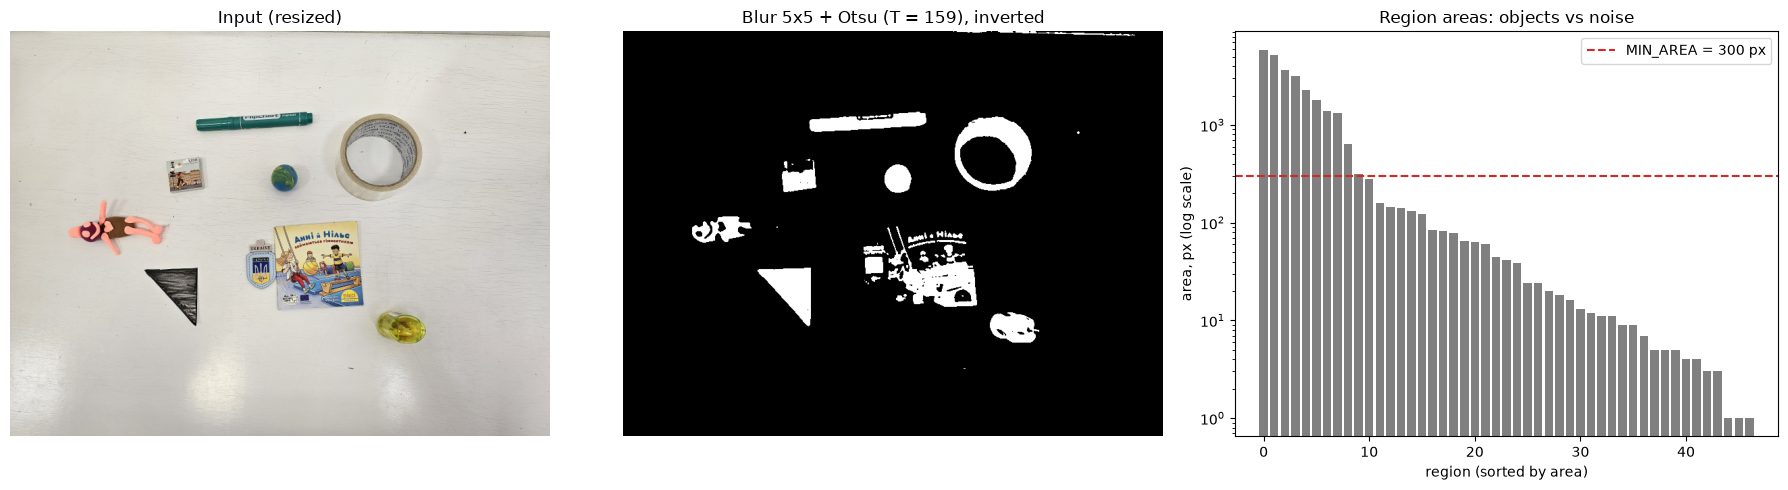

In [ ]:
# defining function to count the number of connected components in the binary mask
# using binary image and minimum area threshold to filter out small regions
# As otsu turned the image in black and white,
#  we can use connected components to count the number of objects in the image
def count_objects(mask, min_area=MIN_AREA):
    """Number of white connected regions with area >= min_area, and total number of regions."""
    n, labels, stats, centroids = cv2.connectedComponentsWithStats(mask, connectivity=8)
    areas = stats[1:, cv2.CC_STAT_AREA]                 # skip label 0 = background
    return int((areas >= min_area).sum()), len(areas)
# cv2.connectedComponentsWithStats return 
# labels, stats, centroids, and the number of connected components (n)
# Labels are number of seperated white objects, 
#  
n_obj, n_all = count_objects(binary)
areas = np.sort(cv2.connectedComponentsWithStats(binary, connectivity=8)[2][1:, cv2.CC_STAT_AREA])[::-1]
print(f"Before morphology: {n_all} regions in total, {n_obj} with area >= {MIN_AREA} px "
      f"(ground truth: {GROUND_TRUTH})")
print("Largest 12 region areas, px:", areas[:12].tolist())

# displaying the input image, binary mask, and a bar chart of region areas
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
axes[0].set_title("Input (resized)")
axes[1].imshow(binary, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Blur 5x5 + Otsu (T = {t_otsu:.0f}), inverted")
axes[2].bar(range(len(areas)), areas, color="gray")
axes[2].axhline(MIN_AREA, color="tab:red", linestyle="--", label=f"MIN_AREA = {MIN_AREA} px")
axes[2].set_yscale("log")
axes[2].set_xlabel("region (sorted by area)")
axes[2].set_ylabel("area, px (log scale)")
axes[2].set_title("Region areas: objects vs noise")
axes[2].legend()
for ax in axes[:2]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task03_step1_binary.png", dpi=150, bbox_inches="tight")
plt.show()

The 15 morphology results - 5 operations x 3 kernel sizes = 15 results

Operation   kernel  objects  regions  white %  (ground truth 9)
Erosion        3x3       10       63      4.5
Erosion        5x5        9       30      3.6
Erosion        9x9        8       17      2.2
Dilation       3x3       13       31      7.0
Dilation       5x5       10       19      8.1
Dilation       9x9       10       13     10.0
Opening        3x3       10       51      5.6
Opening        5x5       10       25      5.2
Opening        9x9       10       13      4.4
Closing        3x3       11       35      5.8
Closing        5x5       10       23      6.1
Closing        9x9        9       14      6.5
Gradient       3x3       13       54      2.5
Gradient       5x5       12       31      4.5
Gradient       9x9       10       15      7.8


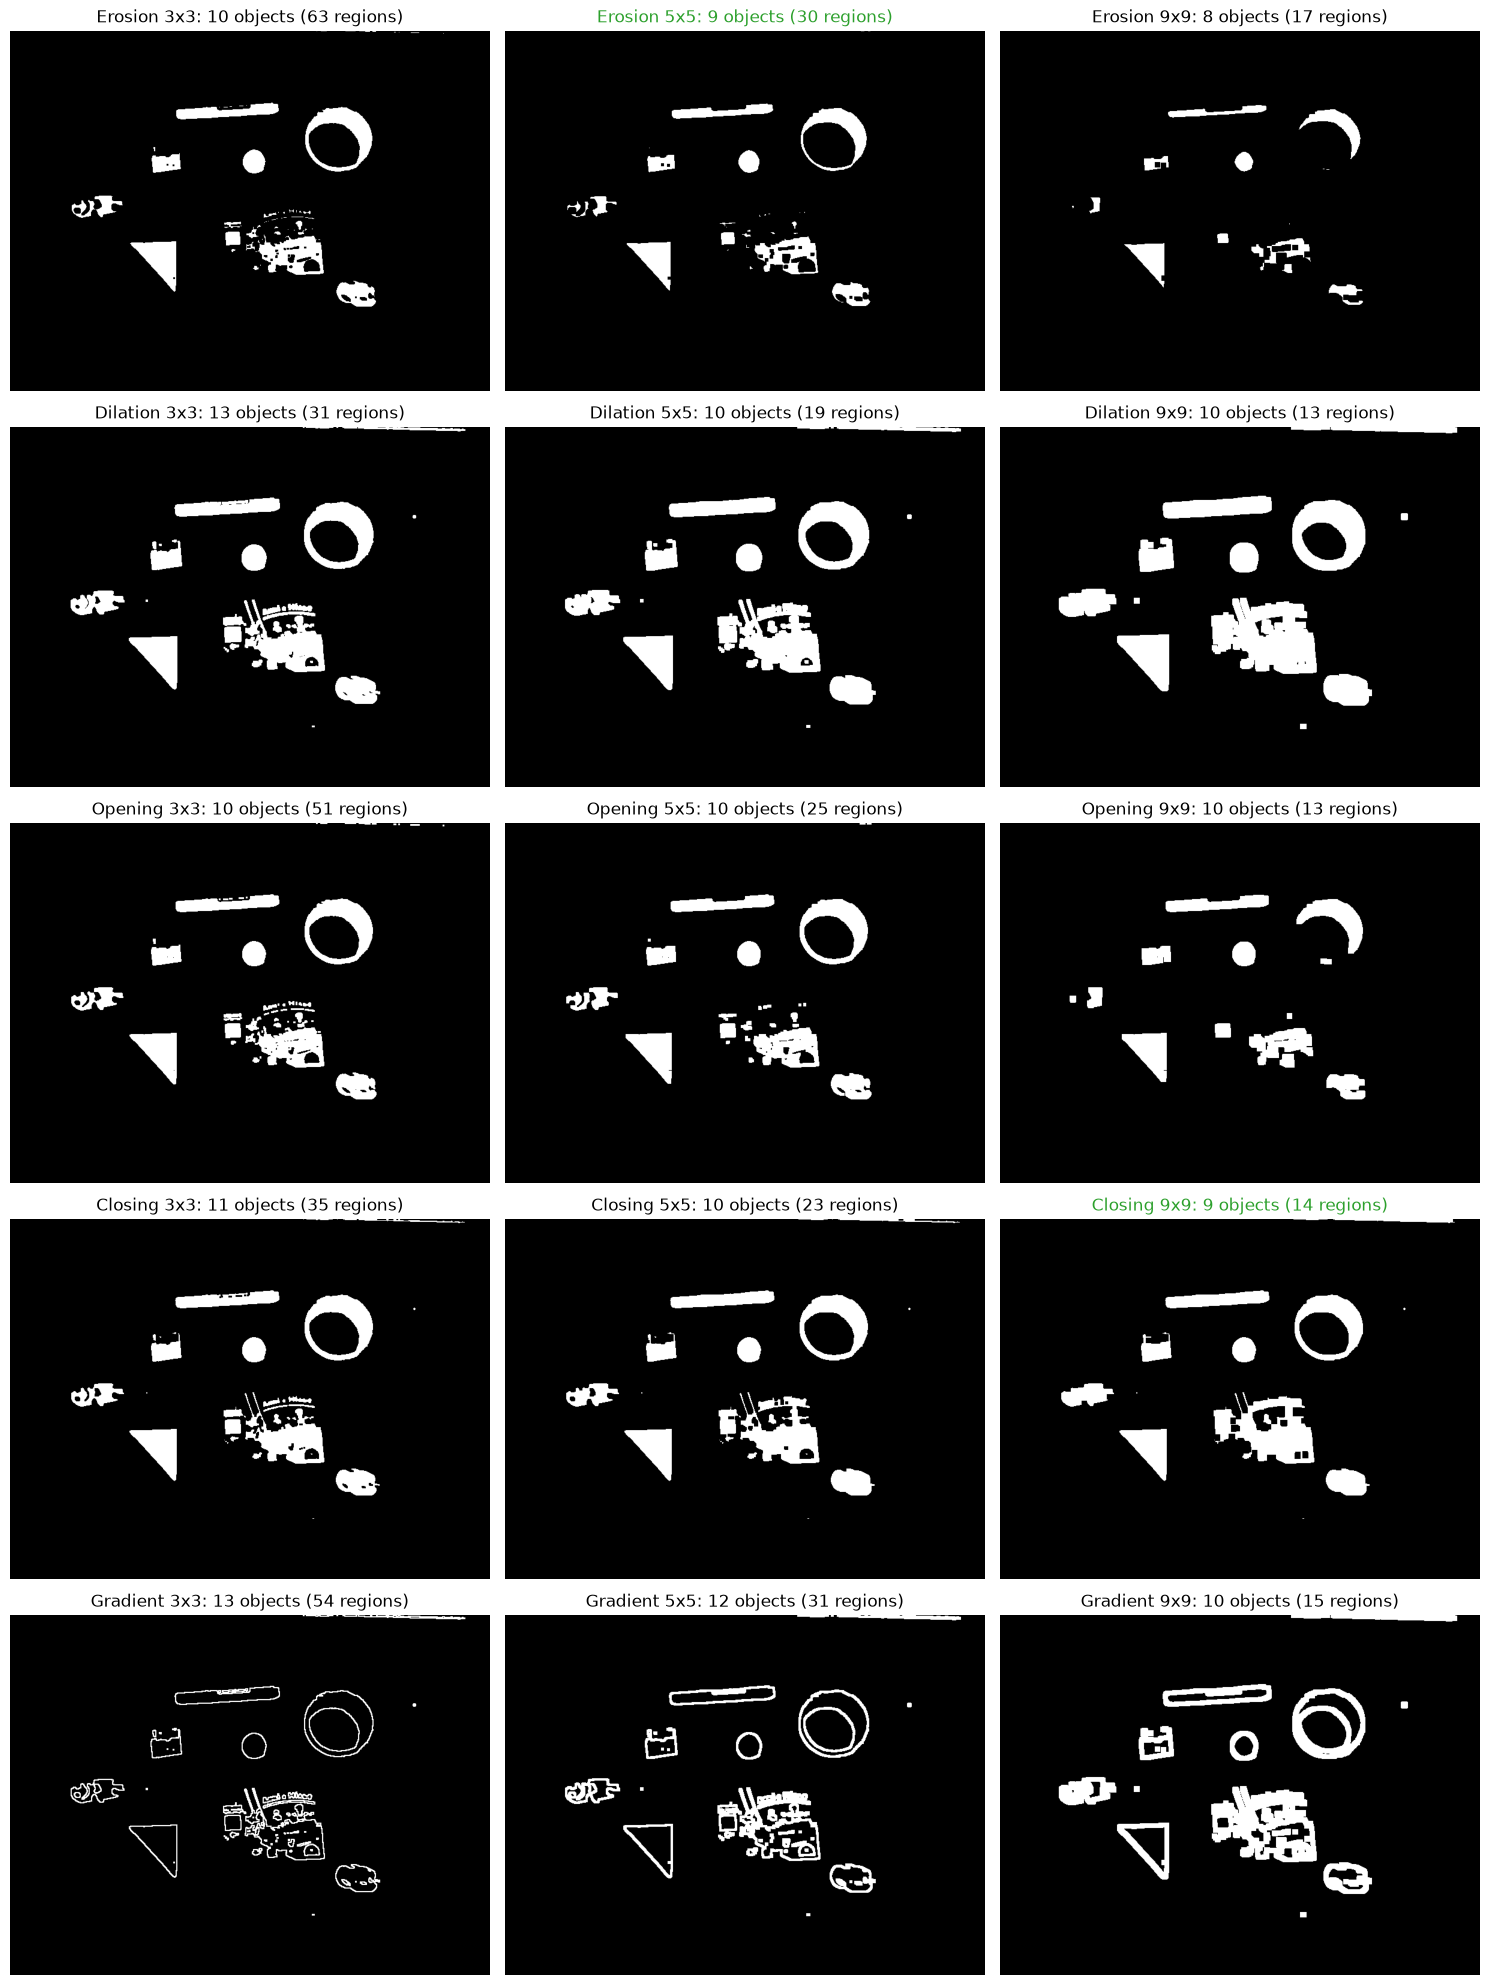

In [5]:
# Cell 4 — 5 operations x 3 kernel sizes = 15 results
KSIZES = [3, 5, 9]
OPERATIONS = {
    "Erosion":  lambda m, k: cv2.erode(m, k, iterations=1),
    "Dilation": lambda m, k: cv2.dilate(m, k, iterations=1),
    "Opening":  lambda m, k: cv2.morphologyEx(m, cv2.MORPH_OPEN, k),
    "Closing":  lambda m, k: cv2.morphologyEx(m, cv2.MORPH_CLOSE, k),
    "Gradient": lambda m, k: cv2.morphologyEx(m, cv2.MORPH_GRADIENT, k),
}

morph = {}            # (operation, k) -> result image
morph_rows = []       # rows for the CSV table
fig, axes = plt.subplots(len(OPERATIONS), len(KSIZES), figsize=(15, 20))
print(f"{'Operation':<10}{'kernel':>8}{'objects':>9}{'regions':>9}{'white %':>9}  (ground truth {GROUND_TRUTH})")
for i, (name, fn) in enumerate(OPERATIONS.items()):
    for j, k in enumerate(KSIZES):
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (k, k))
        result = fn(binary, kernel)
        morph[(name, k)] = result
        n_obj, n_all = count_objects(result)
        wp = 100 * cv2.countNonZero(result) / result.size
        morph_rows.append([name, f"{k}x{k}", n_obj, n_all, round(wp, 1)])
        print(f"{name:<10}{f'{k}x{k}':>8}{n_obj:>9}{n_all:>9}{wp:>9.1f}")
        _ = cv2.imwrite(str(RESULTS_DIR / f"task03_{name.lower()}_{k}x{k}.png"), result)

        ax = axes[i, j]
        ax.imshow(result, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{name} {k}x{k}: {n_obj} objects ({n_all} regions)",
                     color="tab:green" if n_obj == GROUND_TRUTH else "black")
        ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task03_step2_morphology_grid.png", dpi=110, bbox_inches="tight")
plt.show()

with open(RESULTS_DIR / "task03_morphology_counts.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["operation", "kernel", "objects_ge_min_area", "all_regions", "white_pct"])
    w.writerows(morph_rows)

Automatic object counter with labelled boxes

=== Automatic count: opening 5x5 -> closing 9x9 ===
Detected objects: 9   (ground truth: 9)
  #1: x=276 y=119 w=173 h= 30 area= 3064 px
  #2: x=387 y=197 w= 39 h= 42 area= 1326 px
  #3: x=491 y=127 w=114 h=109 area= 5228 px
  #4: x=102 y=274 w= 86 h= 39 area= 2094 px
  #5: x=235 y=205 w= 50 h= 33 area= 1380 px
  #6: x=201 y=350 w= 77 h= 85 area= 3661 px
  #7: x=356 y=318 w= 30 h= 51 area=  962 px
  #8: x=400 y=316 w=124 h= 92 area= 5538 px
  #9: x=543 y=417 w= 68 h= 44 area= 2358 px


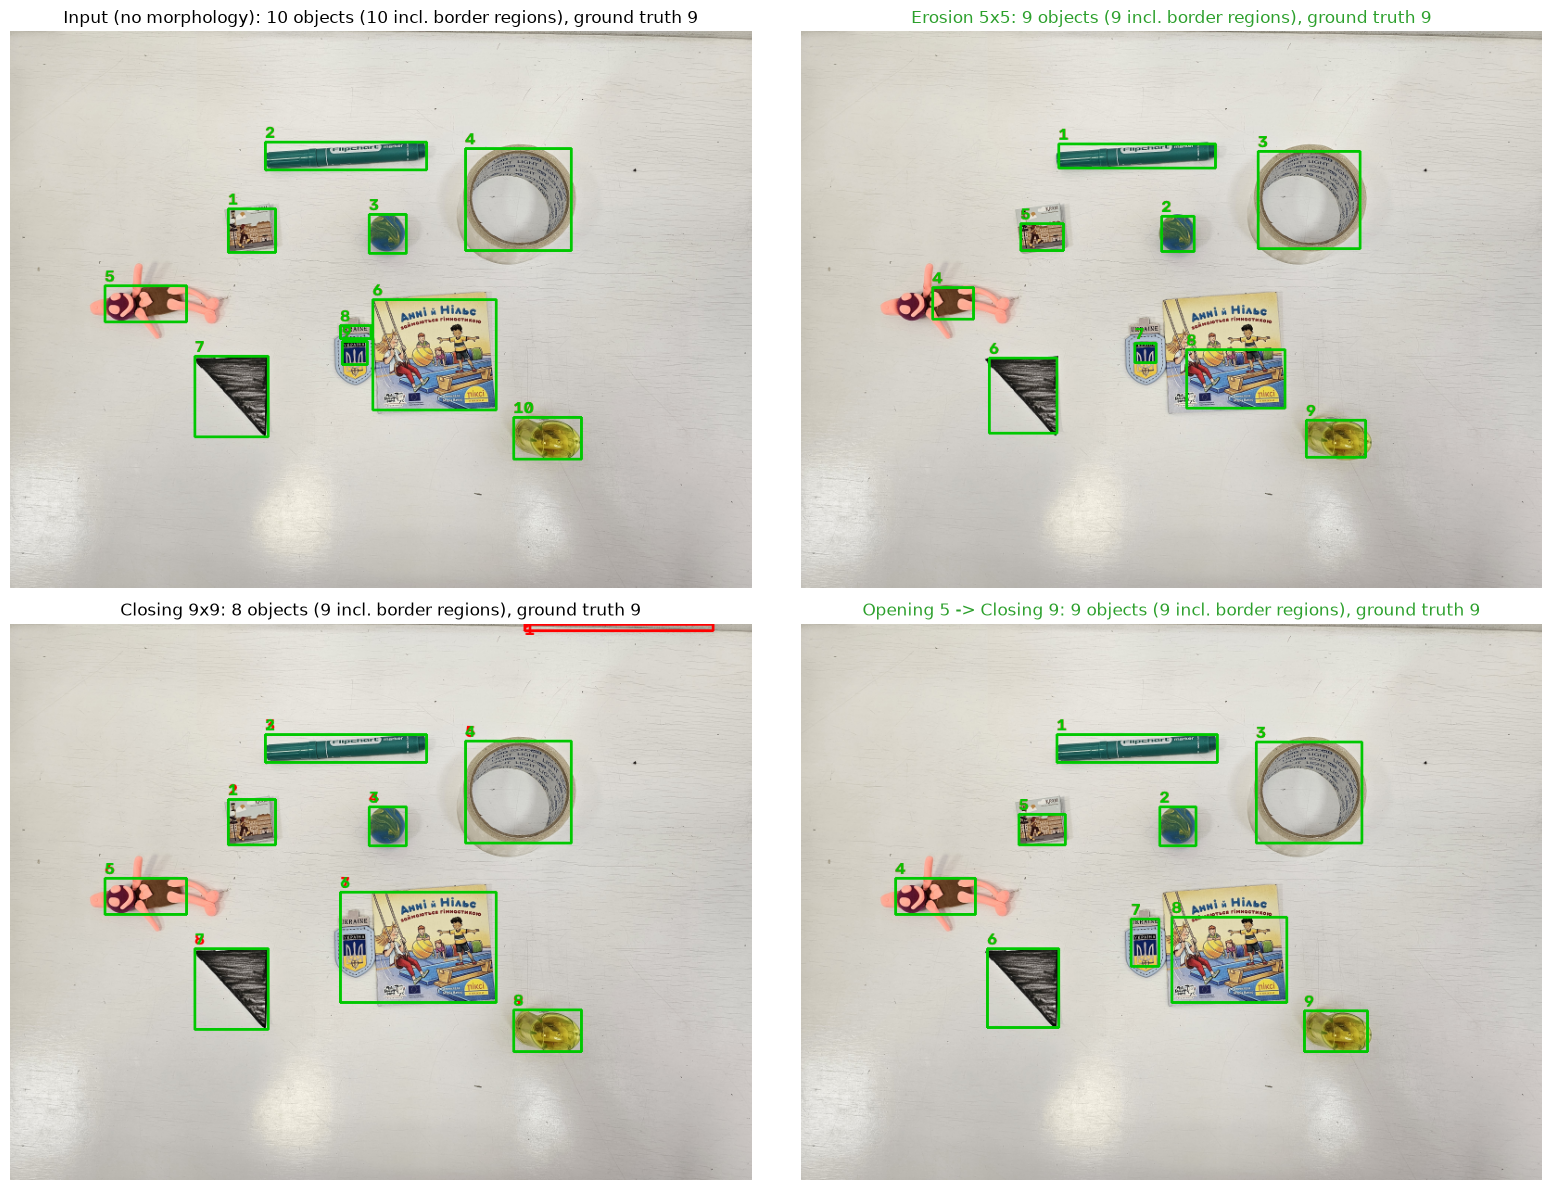

In [ ]:
# Cell 5   
OPEN_K, CLOSE_K = 5, 9            # chosen pipeline: opening 5x5, then closing 9x9
EXCLUDE_BORDER = True             # ignore regions touching the image border (edge artefacts)

def find_objects(mask, min_area=MIN_AREA, exclude_border=EXCLUDE_BORDER):
    """Return list of (x, y, w, h, area) for valid objects."""
    H, W = mask.shape
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    objects = []
    for x, y, w, h, area in stats[1:]:
        if area < min_area:
            continue
        if exclude_border and (x == 0 or y == 0 or x + w >= W or y + h >= H):
            continue
        objects.append((int(x), int(y), int(w), int(h), int(area)))
    return sorted(objects, key=lambda o: (o[1] // 100, o[0]))     # rough top-to-bottom, left-to-right

def count_after_morphology(binary_img, open_k=OPEN_K, close_k=CLOSE_K):
    """The automatic counter required by the lab: opening -> closing -> labelled objects."""
    k_open = cv2.getStructuringElement(cv2.MORPH_RECT, (open_k, open_k))
    k_close = cv2.getStructuringElement(cv2.MORPH_RECT, (close_k, close_k))
    cleaned = cv2.morphologyEx(binary_img, cv2.MORPH_OPEN, k_open)
    cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_CLOSE, k_close)
    return cleaned, find_objects(cleaned)

def draw_objects(bgr, objects, color=(0, 200, 0)):
    out = bgr.copy()
    for i, (x, y, w, h, area) in enumerate(objects, start=1):
        cv2.rectangle(out, (x, y), (x + w, y + h), color, 2)
        cv2.putText(out, str(i), (x, max(y - 4, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return out

final_mask, final_objects = count_after_morphology(binary)
_ = cv2.imwrite(str(RESULTS_DIR / "task03_final_mask.png"), final_mask)

print(f"=== Automatic count: opening {OPEN_K}x{OPEN_K} -> closing {CLOSE_K}x{CLOSE_K} ===")
print(f"Detected objects: {len(final_objects)}   (ground truth: {GROUND_TRUTH})")
for i, (x, y, w, h, a) in enumerate(final_objects, start=1):
    print(f"  #{i}: x={x:3d} y={y:3d} w={w:3d} h={h:3d} area={a:5d} px")

# --- compare with single operations that also give "9" or close to it ---
cases = [
    ("Input (no morphology)", binary),
    ("Erosion 5x5",  morph[("Erosion", 5)]),
    ("Closing 9x9",  morph[("Closing", 9)]),
    (f"Opening {OPEN_K} -> Closing {CLOSE_K}", final_mask),
]
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for ax, (title, m) in zip(axes.ravel(), cases):
    objs_all = find_objects(m, exclude_border=False)
    objs = find_objects(m)
    vis = draw_objects(resized, objs_all, color=(0, 0, 255))      # all regions >= MIN_AREA: red
    vis = draw_objects(vis, objs, color=(0, 200, 0))               # valid objects: green (on top)
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{title}: {len(objs)} objects "
                 f"({len(objs_all)} incl. border regions), ground truth {GROUND_TRUTH}",
                 color="tab:green" if len(objs) == GROUND_TRUTH else "black")
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task03_step3_object_counter.png", dpi=130, bbox_inches="tight")
plt.show()

sensitivity of the count to the pipeline kernel sizes

  open  close  objects  correct
   3x3    5x5       10       no
   3x3    9x9        8       no
   3x3   15x15        8       no
   5x5    5x5        9      yes
   5x5    9x9        9      yes
   5x5   15x15        8       no
   7x7    5x5       10       no
   7x7    9x9        9      yes
   7x7   15x15        9      yes


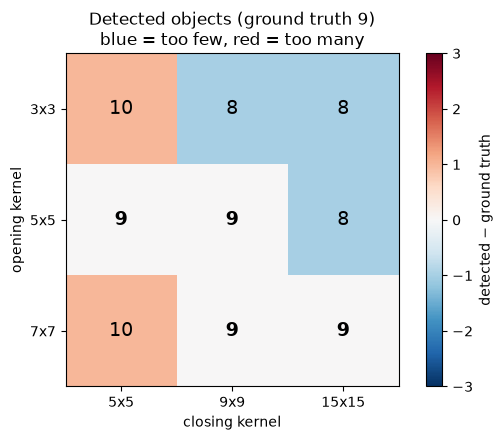

In [7]:
# Cell 6 — Step 4: sensitivity of the count to the pipeline kernel sizes
OPEN_SIZES = [3, 5, 7]
CLOSE_SIZES = [5, 9, 15]

grid_counts = np.zeros((len(OPEN_SIZES), len(CLOSE_SIZES)), dtype=int)
pipeline_rows = []
print(f"{'open':>6}{'close':>7}{'objects':>9}{'correct':>9}")
for i, ko in enumerate(OPEN_SIZES):
    for j, kc in enumerate(CLOSE_SIZES):
        _, objs = count_after_morphology(binary, open_k=ko, close_k=kc)
        grid_counts[i, j] = len(objs)
        ok = len(objs) == GROUND_TRUTH
        pipeline_rows.append([f"{ko}x{ko}", f"{kc}x{kc}", len(objs), ok])
        print(f"{ko:>4}x{ko}{kc:>5}x{kc}{len(objs):>9}{'yes' if ok else 'no':>9}")

with open(RESULTS_DIR / "task03_pipeline_sensitivity.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["opening_kernel", "closing_kernel", "objects", "equals_ground_truth"])
    w.writerows(pipeline_rows)

fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(grid_counts - GROUND_TRUTH, cmap="RdBu_r", vmin=-3, vmax=3)
for i in range(len(OPEN_SIZES)):
    for j in range(len(CLOSE_SIZES)):
        ax.text(j, i, grid_counts[i, j], ha="center", va="center", fontsize=14,
                fontweight="bold" if grid_counts[i, j] == GROUND_TRUTH else "normal")
ax.set_xticks(range(len(CLOSE_SIZES)), [f"{k}x{k}" for k in CLOSE_SIZES])
ax.set_yticks(range(len(OPEN_SIZES)), [f"{k}x{k}" for k in OPEN_SIZES])
ax.set_xlabel("closing kernel")
ax.set_ylabel("opening kernel")
ax.set_title(f"Detected objects (ground truth {GROUND_TRUTH})\nblue = too few, red = too many")
fig.colorbar(im, ax=ax, label="detected − ground truth")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task03_step4_pipeline_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()